# 00 — Archive inventory and acquisition QC

Start here. Edit **analysis_workflow.json** once for all notebooks. The default is a reproducible four-file pilot, one recording day/file per May–August month. Set selection mode to `all` for full discovery; remove any file limit before interpreting archive-wide coverage. Every table/figure states its scope.

This reads original waveform samples sequentially. It does not alter the archive, calibrate counts or correct clocks. Triggered-file coverage is not station uptime, and file counts are not an unbiased earthquake rate. See **ANALYSIS_NOTEBOOKS.md** for the sequence and **METRIC_SCHEMA.md** for conventions.

In [1]:
from pathlib import Path
import sys
_candidates = [Path.cwd(), Path.cwd() / '20_analysis', *Path.cwd().parents]
ANALYSIS_DIR = next((p for p in _candidates if (p / 'analysis_workflow.py').is_file()), None)
if ANALYSIS_DIR is None:
    raise FileNotFoundError('Start in 20_analysis or its project root, beside analysis_workflow.py.')
if str(ANALYSIS_DIR) not in sys.path:
    sys.path.insert(0, str(ANALYSIS_DIR))
from analysis_workflow import load_context, describe_context
from IPython.display import display, Image, Markdown
import matplotlib.pyplot as plt
import pandas as pd
ctx = load_context(ANALYSIS_DIR)
display(describe_context(ctx))


,run_id,scope,selected_files,waveform_root,products,time_basis,amplitude_units
0,e75d49b2bf48,pilot_selected_recordings,4,/Users/glennthompson/Library/CloudStorage/Box-...,/Users/glennthompson/Developer/Pinatubo1991Sei...,RECORDED_CLOCK_UNCORRECTED,counts; unknown end-to-end response


## Inventory, read failures and sampling

The inventory retains auxiliary channels separately, checks missing samples, flat prefixes/suffixes, repeated extrema, record lengths and a narrowband 40.5-Hz screen. Repeated extrema suggest possible clipping; they do not establish ADC saturation without hardware limits. A narrowband peak does not identify its origin. A `not_testable` result is not an absence result. Zero-filled gaps inherited from conversion cannot reliably be recovered.

In [2]:
from analysis_workflow import build_inventory
FORCE_REBUILD = False
inventory, files = build_inventory(ctx, force=FORCE_REBUILD)
display(files)
columns = ['trace_key', 'trace_id', 'is_waveform', 'sampling_rate_hz', 'duration_s',
           'missing_samples', 'flat_prefix_s', 'flat_suffix_s', 'repeated_extreme_run_samples',
           'artifact_status', 'artifact_detected', 'artifact_peak_hz', 'artifact_psd_ratio',
           'gain_epoch_id', 'epoch_status', 'qc_flags']
display(inventory[columns])
display(pd.read_csv(ctx['out'] / 'segment_gaps.csv'))


,file,record_id,size,mtime_ns,source_fingerprint,status,error,waveform_traces,input_traces
0,/Users/glennthompson/Library/CloudStorage/Box-...,ccdc18d400ed,589824,1764638868000000000,d227c13c6afd2d8124f139ee4f88a3fb380a51518842f7...,read_ok,,9,9
1,/Users/glennthompson/Library/CloudStorage/Box-...,11528bd4cb1c,262144,1764646075000000000,19e2b11d07b949bf3bca724f785f746468586e810de2eb...,read_ok,,4,4
2,/Users/glennthompson/Library/CloudStorage/Box-...,fdef7378dd9a,458752,1764641411000000000,eaa6117897c6f2f421e015ab028d92c984eba8b4873f99...,read_ok,,7,7
3,/Users/glennthompson/Library/CloudStorage/Box-...,e6d54cae857d,458752,1764644457000000000,778f967e215427d805a3a1b2744de605011bd3106fa279...,read_ok,,7,7


,trace_key,trace_id,is_waveform,sampling_rate_hz,duration_s,missing_samples,flat_prefix_s,flat_suffix_s,repeated_extreme_run_samples,artifact_status,artifact_detected,artifact_peak_hz,artifact_psd_ratio,gain_epoch_id,epoch_status,qc_flags
0,ccdc18d400ed:0,XB.GRN..EHZ,True,100.0,76.8,0,0.01,0.01,1,ok,True,40.429688,387.177641,GRN.EHZ:1991-05-14:1991-06-16,provisional_recorded_time_match,
1,ccdc18d400ed:1,XB.UBO..EHZ,True,100.0,76.8,0,0.01,0.01,1,ok,True,40.429688,1935.912368,UBO.EHZ:1991-05-01:1991-06-11T14:00:00,provisional_recorded_time_match,
2,ccdc18d400ed:2,XB.PIE..EHZ,True,100.0,76.8,0,0.01,0.01,1,ok,True,40.429688,74422.644715,PIE.EHZ:1991-04-30:1991-06-16,provisional_recorded_time_match,
3,ccdc18d400ed:3,XB.PPO..EHE,True,100.0,76.8,0,0.01,0.01,1,ok,True,40.429688,15455.716019,PPO.EHE:1991-05-12:1991-06-12,provisional_recorded_time_match,
4,ccdc18d400ed:4,XB.PPO..EHZ,True,100.0,76.8,0,0.01,0.01,1,ok,True,40.429688,9926.754301,PPO.EHZ:1991-05-12:1991-05-30,provisional_recorded_time_match,
5,ccdc18d400ed:5,XB.BUR..EHZ,True,100.0,76.8,0,0.01,0.01,1,ok,True,40.429688,1772.437756,BUR.EHZ:1991-05-05:1991-06-12,provisional_recorded_time_match,
6,ccdc18d400ed:6,XB.PPO..EHN,True,100.0,76.8,0,0.01,0.02,1,ok,True,40.429688,1382.258918,PPO.EHN:1991-05-12:1991-06-12,provisional_recorded_time_match,
7,ccdc18d400ed:7,XB.CAB..EHZ,True,100.0,76.8,0,0.01,0.01,1,ok,True,40.429688,1361.003777,CAB.EHZ:1991-05-05T04:45:00:1991-06-16,provisional_recorded_time_match,
8,ccdc18d400ed:8,XB.BUG..EHZ,True,100.0,76.8,0,0.01,0.01,1,ok,True,40.429688,6401.615750,BUG.EHZ:1991-05-11:1991-06-16,provisional_recorded_time_match,
9,11528bd4cb1c:0,XB.BUG..EHZ,True,100.0,76.8,0,0.01,0.01,1,ok,True,40.673828,459.810477,BUG.EHZ:1991-05-11:1991-06-16,provisional_recorded_time_match,


,record_id,trace_id,start,end,gap_seconds,gap_samples


## Selected-record coverage and quality screens

Colours and typography are shared with subsequent notebooks. Figures are saved as 300-dpi PNG plus PDF/SVG, with a caption beside each. Sampling-rate changes, padding and gain epochs must be considered before comparing metrics.

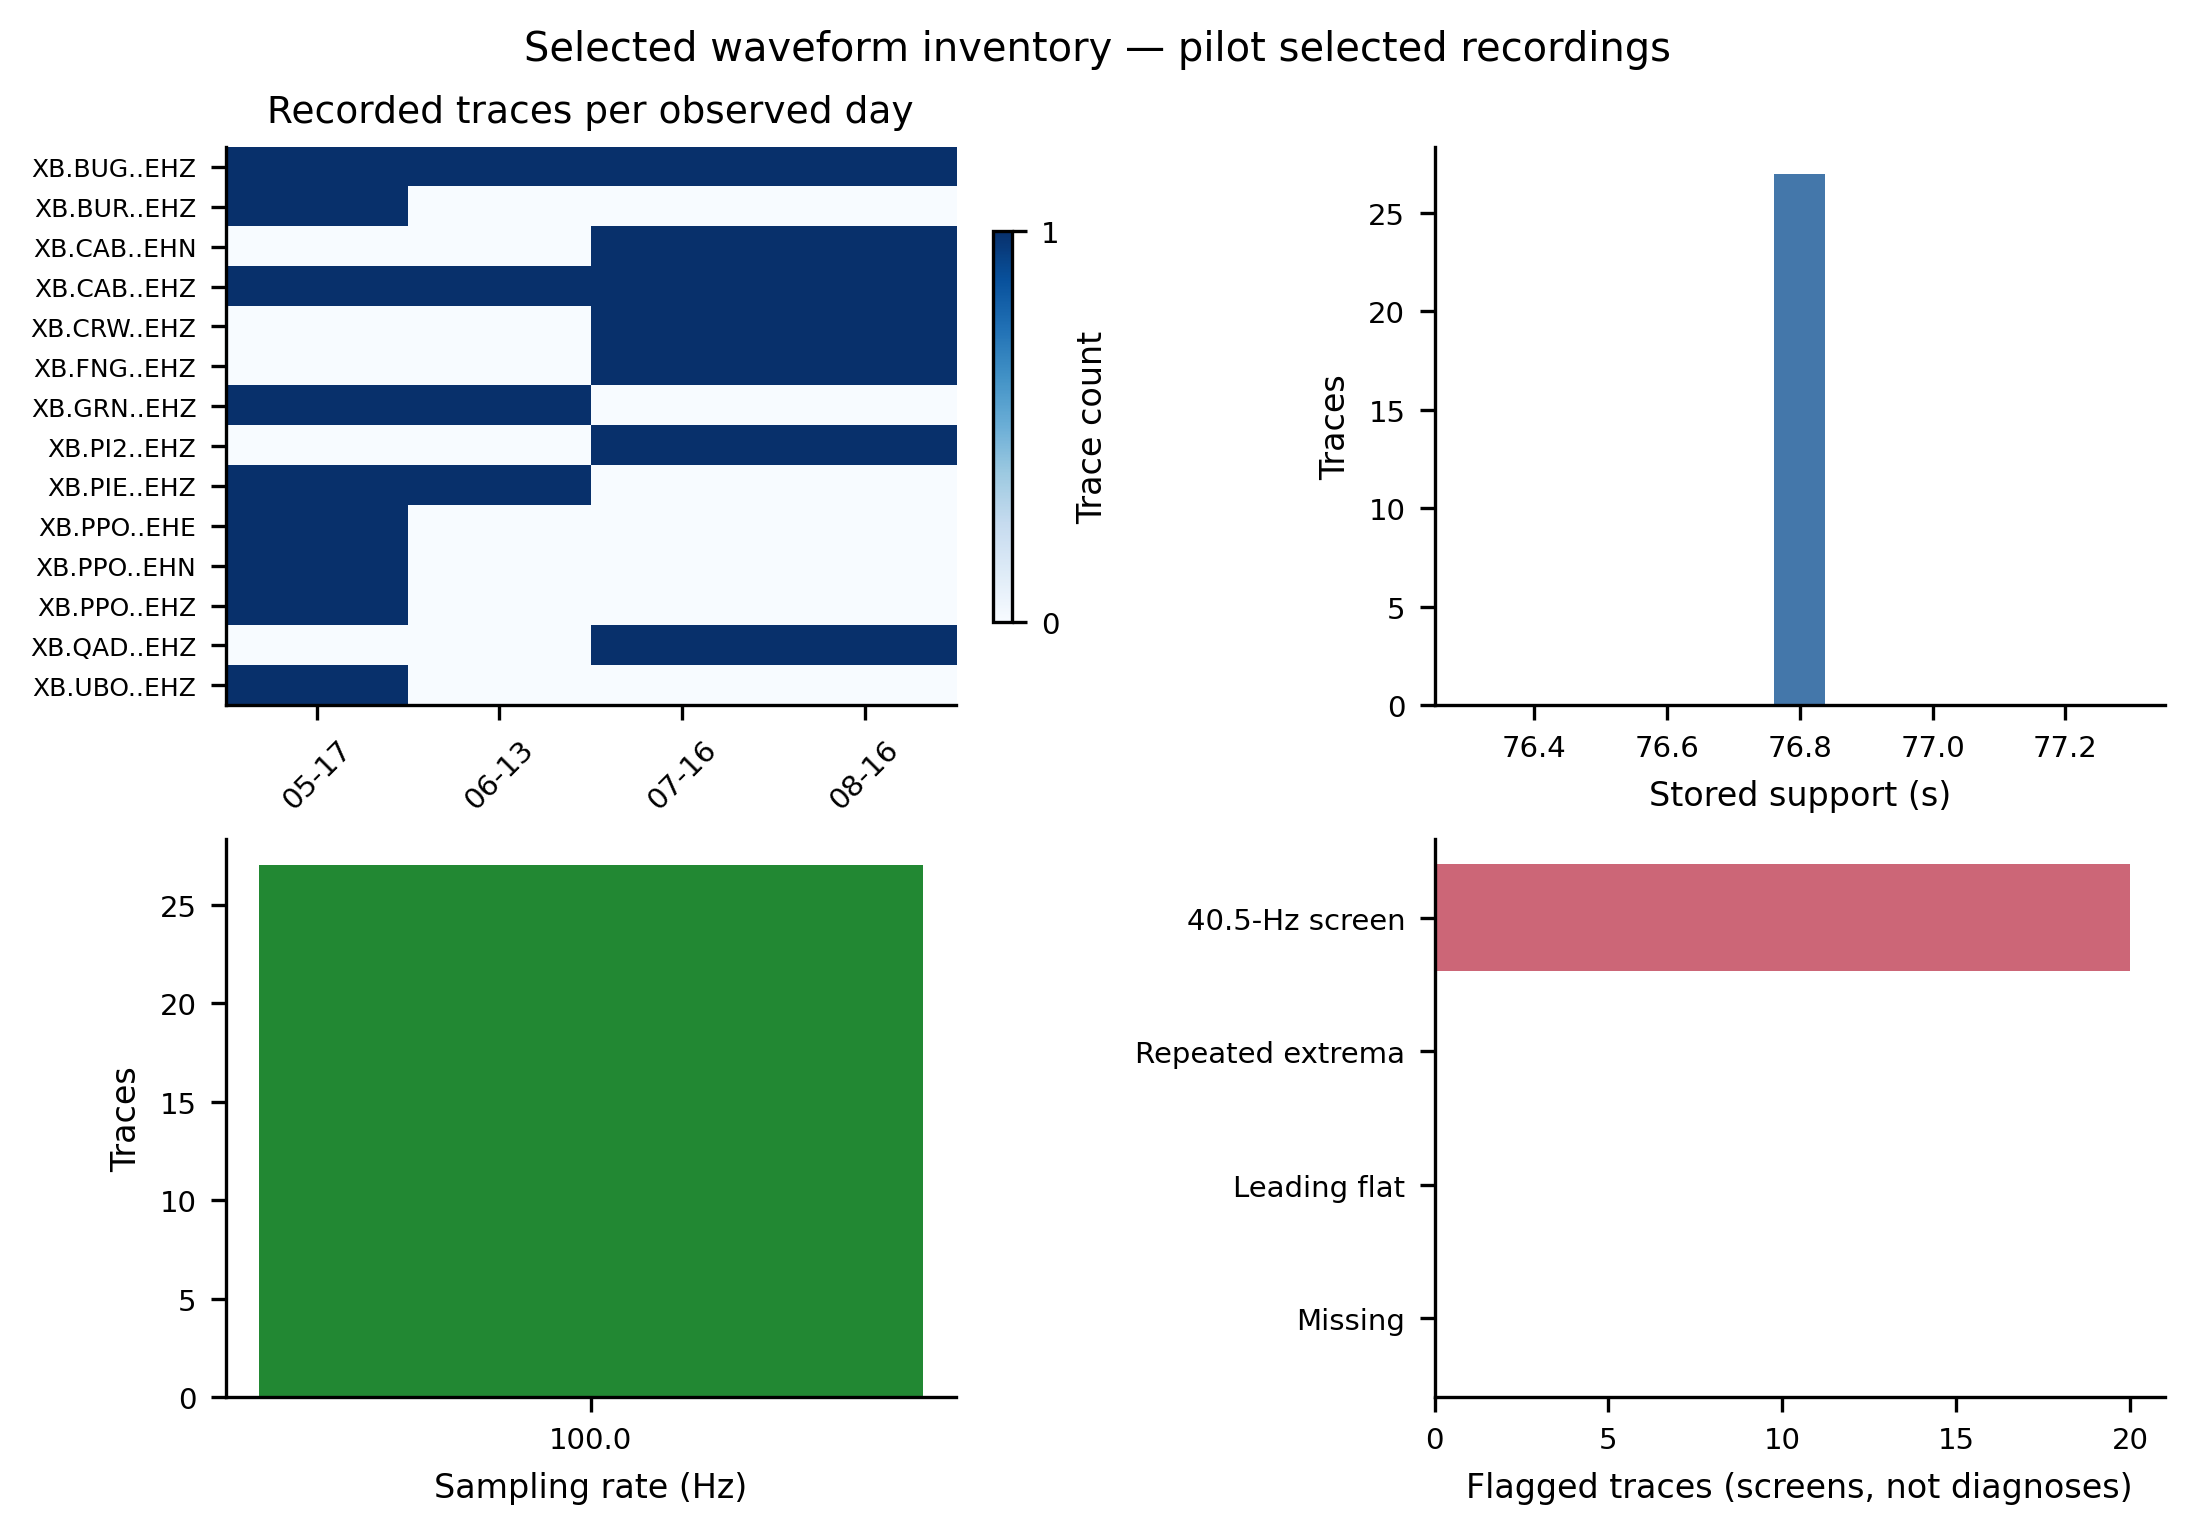

Inventory and provenance: /Users/glennthompson/Developer/Pinatubo1991SeismicData/20_analysis/products/notebook_workflow/e75d49b2bf48


In [3]:
from analysis_workflow import plot_inventory
fig = plot_inventory(ctx, inventory)
display(Image(filename=str(ctx['out'] / 'figures/archive_inventory.png')))
plt.close(fig)
print('Inventory and provenance:', ctx['out'])


Next: **10_stationxml_and_network.ipynb**, then **20_pretrigger_and_window_selection.ipynb**. The older combined `00_archive_qc_and_pretrigger.ipynb` remains available as an earlier exploratory notebook; this sequence does not depend on it.